Checkpoint #2 

Part a

In [7]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

churn = pd.read_csv('netflix_customer_churn.csv')

churn["watch_hours"] = churn["watch_hours"].round().astype(int)
churn = churn[churn["avg_watch_time_per_day"] <= 24]          # impossible values

# Checking to see if the data look right (Can delete later or use for outliers)
#churn.boxplot(column=["watch_hours", "avg_watch_time_per_day"])
#plt.show()



Do the customers who churn watch fewer hours of Netflix than those who are still subscribed? 

Subscribed mean: 17.35
Churned mean: 5.91


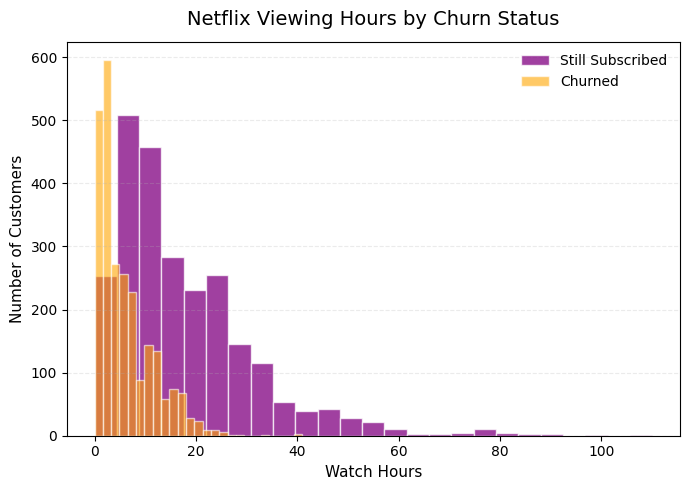

In [41]:
# Separate viewing hours by churn status
subscribed = churn[churn["churned"] == 0]["watch_hours"].dropna()
churned = churn[churn["churned"] == 1]["watch_hours"].dropna()

print("Subscribed mean:", round(subscribed.mean(), 2))
print("Churned mean:", round(churned.mean(), 2))

# Create box plot
plt.figure(figsize=(7, 5))

plt.hist(subscribed, bins=25, alpha=0.75, label="Still Subscribed",
         edgecolor="white", linewidth=1, color="purple")

plt.hist(churned, bins=25, alpha=0.6, label="Churned",
         edgecolor="white", linewidth=1, color="orange")

plt.title("Netflix Viewing Hours by Churn Status", fontsize=14, pad=12)
plt.xlabel("Watch Hours", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)

plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [36]:
t_stat, p_value = stats.ttest_ind(churned, subscribed, equal_var=False, alternative="less")

print("t-statistic:", round(t_stat, 4))
print("p-value:", f"{p_value:.2e}")

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print(
        f"The hypothesis test produced a t-statistic of {t_stat:.4f} "
        f"and a p-value of {p_value:.2e}, which is smaller than 0.05. "
        "Therefore, we reject the null hypothesis. There is statistically "
        "significant evidence to say that customers who churn watch fewer hours "
        "of Netflix than customers who remain subscribed."
    )
else:
    print("Fail to reject the null hypothesis.")
    print(
        f"The hypothesis test produced a t-statistic of {t_stat:.4f} "
        f"and a p-value of {p_value:.2e}, which is greater than or equal "
        "to 0.05. Therefore, we fail to reject the null hypothesis. "
        "There is insufficient statistical evidence to say that customers who "
        "churn watch fewer hours of Netflix than customers who remain subscribed."
    )

t-statistic: -38.3832
p-value: 6.20e-266
Reject the null hypothesis.
The hypothesis test produced a t-statistic of -38.3832 and a p-value of 6.20e-266, which is smaller than 0.05. Therefore, we reject the null hypothesis. There is statistically significant evidence to say that customers who churn watch fewer hours of Netflix than customers who remain subscribed.
